# Seminário de PLN - Tema 2: Detector de Sentimentos Baseado em Léxico

### **Enunciado**

Classificar textos como positivos, negativos ou neutros. Calcular percentuais de cada classe. Considerar intensificadores como: muito bom, extremamente ruim.

**O que é Tokenizar?**

Em Processamento de Linguagem Natural (NLP), é o processo de dividir textos grandes em unidades menores (palavras ou caracteres) para que algoritmos de inteligência artificial possam entender e analisar a linguagem humana.

In [ ]:
import os
import re
import unicodedata
from collections import Counter

import nltk
import requests
from nltk.tokenize import word_tokenize

# Baixa os pacotes de tokenização do NLTK para a língua portuguesa
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Remove acentos: "ótimo" -> "otimo"
def remove_accents(text: str):
  decomposed = unicodedata.normalize("NFKD", text)
  return "".join(c for c in decomposed if not unicodedata.combining(c))

# Normaliza um conjunto de palavras da mesma forma que os tokens
def normalize_words(words):
  return {remove_accents(word) for word in words}

# Definição dos Léxicos (com formas femininas e plurais)
positive_lexicon = normalize_words({
    "excelente", "excelentes",
    "ótimo", "ótima", "ótimos", "ótimas",
    "bom", "boa", "bons", "boas",
    "rápido", "rápida", "rápidos", "rápidas",
    "eficiente", "eficientes",
    "gostei",
})

negative_lexicon = normalize_words({
    "ruim", "ruins",
    "péssimo", "péssima", "péssimos", "péssimas",
    "lento", "lenta", "lentos", "lentas",
    "horrível", "horríveis",
    "problema", "problemas",
    "falha", "falhas",
})

# Intensificadores
intensifiers = normalize_words({
    "muito", "extremamente", "super", "bastante", "bem",
})

# Negações: invertem a polaridade da palavra seguinte
negations = normalize_words({
    "não", "nunca", "nem", "nada", "jamais",
})

# Palavras que encerram o alcance de uma negação
contrast_words = normalize_words({
    "mas", "porém", "entretanto",
})

NEGATION_WINDOW = 3  # quantidade de tokens anteriores verificados

In [ ]:
# Leitura dos comentários no arquivo .txt
# Usa o arquivo local, se existir; caso contrário (ex.: Colab), baixa do GitHub
def read_comments():
  URL = ("https://raw.githubusercontent.com/pv-Chagas/"
  "uema-actv-lexicon-based-sentiment-analysis/main/docs/comentarios.txt")    # arquivo remoto
  local_paths = (
    "docs/comentarios.txt",       # execução a partir da raiz do projeto
    "../docs/comentarios.txt",    # execução a partir da pasta notebooks/
  )

  for path in local_paths:
    if os.path.isfile(path):
      with open(path, "r", encoding="utf-8") as f:
        text = f.read()
      break
  else:
    response = requests.get(URL, timeout=10)
    response.raise_for_status()   # interrompe em caso de erro (ex.: 404)
    response.encoding = "utf-8"
    text = response.text

  return [line.strip() for line in text.splitlines() if line.strip()]

# Tokenização: Pega os comentários e converte em tokens
def tokenize(text: str):
  cleaned_text = remove_accents(text.lower()) # letras minúsculas e sem acentos
  # remove pontuações, exceto as que separam ideias (usadas na negação)
  cleaned_text = re.sub(r"[^\w\s.,;:!?]", "", cleaned_text)
  tokens = word_tokenize(cleaned_text, language="portuguese")
  return tokens

# Negação: procura uma palavra de negação pouco antes do token
def is_negated(tokens, i):
  for previous in reversed(tokens[max(0, i - NEGATION_WINDOW):i]):
    is_punctuation = not re.search(r"\w", previous)
    if is_punctuation or previous in contrast_words:
      return False
    if previous in negations:
      return True
  return False

# Análise de sentimento: Verifica quais tokens estão nos léxicos
def analyze_sentiment(tokens):
  positive_count = 0
  negative_count = 0
  positive_score = 0
  negative_score = 0

  for i, token in enumerate(tokens):
    if token in positive_lexicon:
      is_positive = True
    elif token in negative_lexicon:
      is_positive = False
    else:
      continue

    if is_negated(tokens, i):
      is_positive = not is_positive

    has_intensifier = i > 0 and tokens[i-1] in intensifiers
    weight = 2 if has_intensifier else 1

    if is_positive:
      positive_count += 1
      positive_score += weight
    else:
      negative_count += 1
      negative_score += weight

  score = positive_score - negative_score

  if score > 0: sentiment_label = "POSITIVO"
  elif score < 0: sentiment_label = "NEGATIVO"
  else: sentiment_label = "NEUTRO"

  return {
      "positive": positive_count,
      "negative": negative_count,
      "score": score,
      "label": sentiment_label,
  }

# Execução do NLP: Rotina principal
def run_nlp_pipeline():
  comments = read_comments()
  total_comments = len(comments)
  class_counts = Counter()

  if total_comments == 0:
    print("Nenhum comentário no arquivo.")
    return

  print("----- ANÁLISE DE CADA COMENTÁRIO -----\n")
  for comment in comments:
    tokens = tokenize(comment)
    result = analyze_sentiment(tokens)
    class_counts[result["label"]] += 1

    print(f"Comentário: {comment}")
    print(f"Positivas: {result['positive']} Negativas: {result['negative']}.", end="\t")
    print(f"Classificação: {result['label']}\n")

  print("----- RESUMO E PERCENTUAIS POR CLASSE -----")
  for label in ("POSITIVO", "NEGATIVO", "NEUTRO"):
    count = class_counts[label]
    percentage = (count / total_comments) * 100
    print(f"{label}: {count} de {total_comments} ({percentage:.2f}%)")

In [ ]:
if __name__ == "__main__":
  run_nlp_pipeline()

----- ANÁLISE DE CADA COMENTÁRIO -----

Comentário: O sistema é excelente e muito rápido.
Positivas: 2 Negativas: 0.	Classificação: POSITIVO

Comentário: O atendimento foi horrível.
Positivas: 0 Negativas: 1.	Classificação: NEGATIVO

Comentário: O produto funciona normalmente.
Positivas: 0 Negativas: 0.	Classificação: NEUTRO

Comentário: O A entrega foi rápida e a equipe é ótima.
Positivas: 2 Negativas: 0.	Classificação: POSITIVO

----- RESUMO E PERCENTUAIS POR CLASSE -----
POSITIVO: 2 de 4 (50.00%)
NEGATIVO: 1 de 4 (25.00%)
NEUTRO: 1 de 4 (25.00%)


## Visualização 1: Palavras destacadas

Cores: **verde** (positiva), **vermelho** (negativa), **laranja** (intensificador) e **roxo** (negação).

A cor indica a categoria original da palavra. Em "não é bom", a palavra "bom" continua verde, mas a negação inverte o resultado.

In [ ]:
import html

from IPython.display import HTML, display

# Cores das categorias de palavras
WORD_COLORS = {
  "Positiva": "#2e7d32",
  "Negativa": "#c62828",
  "Intensificador": "#b45309",
  "Negação": "#6a1b9a",
}

# Cor e ícone de cada classificação
LABEL_STYLES = {
  "POSITIVO": ("#2e7d32", "😊"),
  "NEGATIVO": ("#c62828", "😞"),
  "NEUTRO": ("#616161", "😐"),
}

def badge(text, color):
  return (f'<span style="background:{color};color:white;padding:2px 8px;'
          f'border-radius:6px;white-space:nowrap">{text}</span>')

# Devolve o comentário em HTML, com as palavras reconhecidas coloridas
def highlight(comment):
  categories = (
    (positive_lexicon, "Positiva"),
    (negative_lexicon, "Negativa"),
    (intensifiers, "Intensificador"),
    (negations, "Negação"),
  )
  parts = []
  for part in re.findall(r"\w+|\W+", comment):
    word = remove_accents(part.lower())
    category = next((name for words, name in categories if word in words), None)
    safe = html.escape(part)
    parts.append(badge(safe, WORD_COLORS[category]) if category else safe)
  return "".join(parts)

# Legenda das cores
def legend():
  items = " ".join(badge(name, color) for name, color in WORD_COLORS.items())
  return f'<div style="font-size:12px;margin:4px 0 14px">{items}</div>'

# Cartão com a frase destacada, a classificação e os números da análise
def result_card(comment):
  result = analyze_sentiment(tokenize(comment))
  color, icon = LABEL_STYLES[result["label"]]
  score = f"{result['score']:+d}" if result["score"] else "0"
  return f"""
  <div style="max-width:720px;margin-bottom:12px;padding:14px 18px;
              border:1px solid rgba(128,128,128,0.35);
              border-radius:10px;background:rgba(128,128,128,0.08)">
    <div style="font-size:18px;line-height:2">{highlight(comment)}</div>
    <div style="display:flex;flex-wrap:wrap;align-items:center;gap:16px;
                margin-top:10px;font-size:13px">
      <span style="font-weight:bold">{badge(f"{icon} {result['label']}", color)}</span>
      <span>Positivas: <b>{result['positive']}</b></span>
      <span>Negativas: <b>{result['negative']}</b></span>
      <span>Pontuação: <b>{score}</b></span>
    </div>
  </div>
  """

display(HTML(legend() + "".join(result_card(c) for c in read_comments())))

## Visualização 2: Percentuais por classe

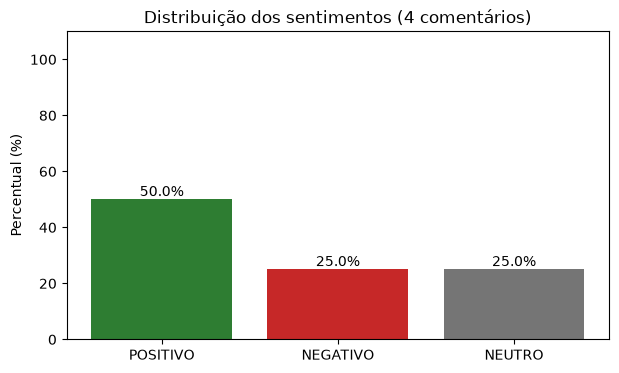

In [ ]:
import matplotlib.pyplot as plt

def plot_percentages(comments):
  if not comments:
    print("Nenhum comentário no arquivo.")
    return

  counts = Counter(analyze_sentiment(tokenize(c))["label"] for c in comments)
  labels = ["POSITIVO", "NEGATIVO", "NEUTRO"]
  percentages = [counts[label] / len(comments) * 100 for label in labels]

  fig, ax = plt.subplots(figsize=(7, 4))
  bars = ax.bar(labels, percentages, color=["#2e7d32", "#c62828", "#757575"])
  ax.bar_label(bars, fmt="%.1f%%")
  ax.set_ylim(0, 110)
  ax.set_ylabel("Percentual (%)")
  ax.set_title(f"Distribuição dos sentimentos ({len(comments)} comentários)")
  plt.show()

plot_percentages(read_comments())

## Visualização 3: Teste ao vivo

Execute a célula abaixo e digite uma frase na caixa que aparecer (no VS Code, no topo da janela). Execute antes a célula da Visualização 1, que define a função `result_card`.

In [ ]:
frase = input("Digite uma frase: ")
display(HTML(legend() + result_card(frase)))